# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


In [3]:

%pip install pandas numpy matplotlib scikit-learn


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\david\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Instancias: 150
Características: 4
Dimensiones X: (150, 4)
Dimensiones y: (150,)

Características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases: ['setosa' 'versicolor' 'virginica']

Ejemplos por clase:
Clase
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Clase
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


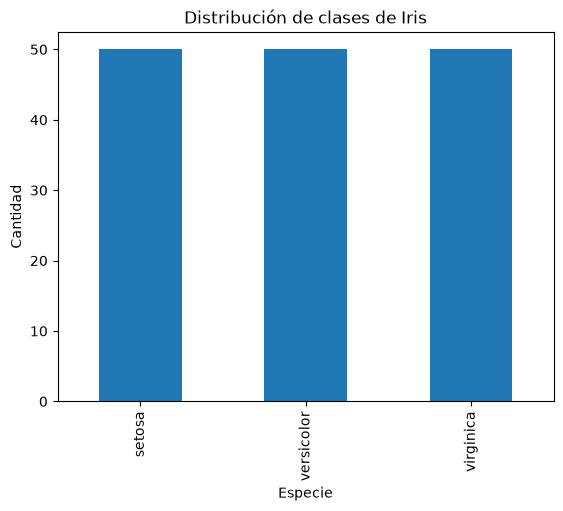

In [4]:

# cargar y explorar Iris
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()
X, y = iris.data, iris.target

# Tabla de características y etiquetas
df = pd.DataFrame(X, columns=iris.feature_names)
df["Clase"] = [iris.target_names[i] for i in y]

print("Instancias:", X.shape[0])
print("Características:", X.shape[1])
print("Dimensiones X:", X.shape)
print("Dimensiones y:", y.shape)
print("\nCaracterísticas:", iris.feature_names)
print("Clases:", iris.target_names)
print("\nEjemplos por clase:")
print(df["Clase"].value_counts())

display(df.head())

# Distribución de clases
df["Clase"].value_counts().plot(kind="bar")
plt.title("Distribución de clases de Iris")
plt.xlabel("Especie")
plt.ylabel("Cantidad")
plt.show()


Cada instancia representa una flor Iris. El dataset contiene 150 instancias con 4 características: largo y ancho del sépalo, y largo y ancho del pétalo, todas en centímetros.

La matriz X tiene dimensiones (150, 4) y el vector de etiquetas y tiene dimensión (150,).

Existen tres clases: setosa, versicolor y virginica, con 50 ejemplos cada una. Por lo tanto, el dataset está balanceado.

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

### Predicciones iniciales

1. **Sensibilidad al escalamiento:** considero que SVM, regresión logística y MLP serán sensibles a las escalas de las características, porque sus cálculos dependen de las magnitudes de las variables.
2. **Fronteras más simples:** espero que SVM lineal y regresión logística produzcan fronteras de decisión más simples, porque utilizan separaciones lineales.
3. **Mejor modelo:** no es posible asegurarlo de antemano porque el rendimiento depende de los datos, los hiperparámetros y la capacidad de generalización de cada algoritmo.

In [5]:

import warnings
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

# Separar entrenamiento (60%), validación (20%) y prueba (20%)
X, y = iris.data, iris.target
X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42
)
X_val, X_te, y_val, y_te = train_test_split(
    X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42
)

modelos = {
    "Naive Bayes": GaussianNB(),
    "Logística": LogisticRegression(max_iter=1000),
    "SVM": SVC(kernel="linear"),
    "Árbol": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(20,), max_iter=1000, random_state=42)
}

# Configuraciones limitadas que compararemos en validación
opciones = {
    "Naive Bayes": [{}, {"var_smoothing": 1e-7}],
    "Logística": [{"C": 1}, {"C": 0.1}],
    "SVM": [{"C": 1}, {"C": 0.1}],
    "Árbol": [{"max_depth": 2}, {"max_depth": 4}],
    "Random Forest": [{"n_estimators": 100, "max_depth": 3},
                      {"n_estimators": 100, "max_depth": None}],
    "Gradient Boosting": [{"n_estimators": 50}, {"n_estimators": 100}],
    "MLP": [{"alpha": 0.001}, {"alpha": 0.1}]
}

finales, configuraciones = {}, {}

for nombre, modelo in modelos.items():
    mejor_f1 = -1

    for config in opciones[nombre]:
        pipe = make_pipeline(StandardScaler(), modelo.set_params(**config))
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pipe.fit(X_tr, y_tr)

        f1 = f1_score(y_val, pipe.predict(X_val), average="macro")

        if f1 > mejor_f1:
            mejor_f1 = f1
            mejor_config = config.copy()

    # Configuración seleccionada sin consultar la prueba
    configuraciones[nombre] = mejor_config
    finales[nombre] = make_pipeline(
        StandardScaler(), modelo.set_params(**mejor_config)
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        finales[nombre].fit(X_tr, y_tr)

print("Modelos entrenados y configuraciones seleccionadas.")


Modelos entrenados y configuraciones seleccionadas.


In [6]:

resultados = []

for nombre, modelo in finales.items():
    pred = modelo.predict(X_te)
    resultados.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros": str(configuraciones[nombre]),
        "Accuracy": round(accuracy_score(y_te, pred), 4),
        "F1 macro": round(f1_score(y_te, pred, average="macro"), 4)
    })

tabla_clasificacion = pd.DataFrame(resultados)
display(tabla_clasificacion)


,Modelo,Transformación,Hiperparámetros,Accuracy,F1 macro
0,Naive Bayes,StandardScaler,{},0.9333,0.9327
1,Logística,StandardScaler,{'C': 1},0.9333,0.9327
2,SVM,StandardScaler,{'C': 1},0.9333,0.9327
3,Árbol,StandardScaler,{'max_depth': 4},0.9000,0.8977
4,Random Forest,StandardScaler,"{'n_estimators': 100, 'max_depth': 3}",0.9667,0.9666
5,Gradient Boosting,StandardScaler,{'n_estimators': 50},0.9667,0.9666
6,MLP,StandardScaler,{'alpha': 0.001},0.9333,0.9327


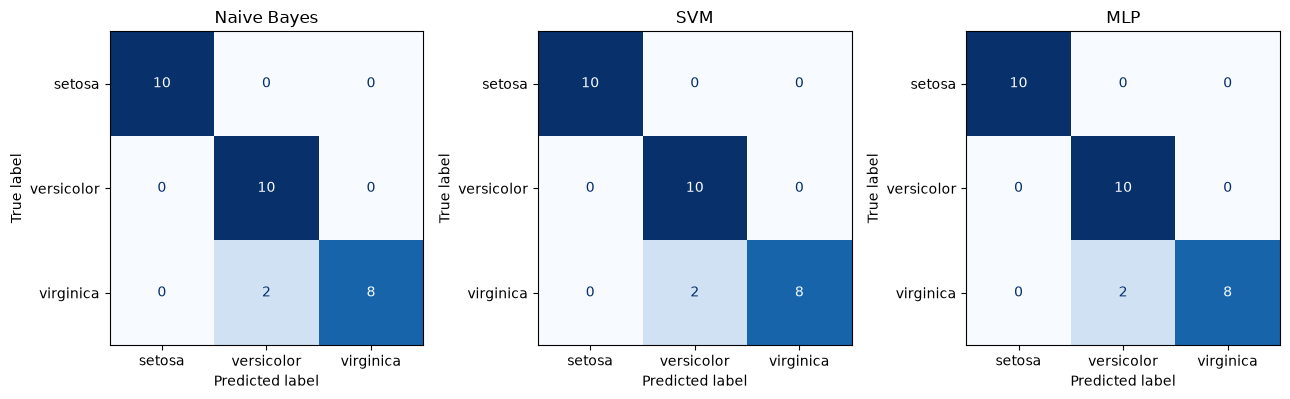

In [7]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, nombre in zip(axes, ["Naive Bayes", "SVM", "MLP"]):
    ConfusionMatrixDisplay.from_estimator(
        finales[nombre], X_te, y_te,
        display_labels=iris.target_names,
        cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(nombre)

plt.tight_layout()
plt.show()


In [8]:

# Reunimos errores de todos los modelos para garantizar dos ejemplos
errores = []

for nombre, modelo in finales.items():
    pred = modelo.predict(X_te)
    for i in range(len(y_te)):
        if pred[i] != y_te[i]:
            errores.append({
                "Modelo": nombre,
                "Real": iris.target_names[y_te[i]],
                "Predicción": iris.target_names[pred[i]],
                **dict(zip(iris.feature_names, X_te[i]))
            })

display(pd.DataFrame(errores).head(2))


,Modelo,Real,Predicción,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,Naive Bayes,virginica,versicolor,6.1,2.6,5.6,1.4
1,Naive Bayes,virginica,versicolor,6.3,2.8,5.1,1.5


### Interpretación

1. **Mejor modelo:** El modelo Gaussiano Naive Bayes fue el mejor con accuracy de 0.933 y F1 macro 0.9327
2. **Modelo más sencillo:** Gaussian Naive Bayes, porque necesita pocos parámetros y se implementa directamente con `GaussianNB()`.
3. **Accuracy y F1 macro:** ambos miden el rendimiento, pero F1 macro considera el equilibrio entre precisión y recall de cada clase. Pueden diferir cuando hay errores desiguales entre las clases.
4. **Macro y micro:** macro calcula la métrica por clase y promedia sin ponderar por cantidad de ejemplos. Micro suma primero los aciertos y errores de todas las clases y calcula una métrica global.
5. **Ventaja del MLP:** puede aprender relaciones no lineales mediante capas ocultas y funciones de activación.

**Análisis de errores:** los ejemplos incorrectamente clasificados muestran que ciertas flores tienen características que el modelo no consigue distinguir correctamente. Podemos examinar si sus medidas son similares a las de otra especie, pero no podemos afirmar la causa exacta del error únicamente observando esos dos ejemplos.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

### Predicción inicial

No considero que un modelo más flexible siempre produzca menor error en datos nuevos. Aunque puede capturar relaciones más complejas, también tiene mayor riesgo de sobreajuste. Un modelo más sencillo puede generalizar mejor si los datos son limitados o contienen ruido.

In [9]:

from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

print("Dimensiones X:", X.shape)
print("Dimensiones y:", y.shape)
print("Variables:", diabetes.feature_names)
print("\nDescripción de las variables:")
print(diabetes.DESCR)

display(pd.DataFrame(X, columns=diabetes.feature_names).head())


Dimensiones X: (442, 10)
Dimensiones y: (442,)
Variables: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Descripción de las variables:
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol /

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [10]:

import numpy as np
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Particiones: 60% entrenamiento, 20% validación, 20% prueba
X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    X, y, test_size=0.4, random_state=42
)
X_val, X_te, y_val, y_te = train_test_split(
    X_tmp, y_tmp, test_size=0.5, random_state=42
)

modelos_reg = {
    "Lineal": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=5000),
    "kNN": KNeighborsRegressor(),
    "Árbol": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "MLP": MLPRegressor(hidden_layer_sizes=(30,), max_iter=1500, random_state=42)
}

opciones_reg = {
    "Lineal": [{}],
    "Ridge": [{"alpha": a} for a in [0.1, 1, 10]],
    "Lasso": [{"alpha": a} for a in [0.01, 0.1, 1]],
    "kNN": [{"n_neighbors": 5}, {"n_neighbors": 15}],
    "Árbol": [{"max_depth": 3}, {"max_depth": 5}],
    "Random Forest": [{"max_depth": 4}, {"max_depth": None}],
    "Gradient Boosting": [{"n_estimators": 50}, {"n_estimators": 100}],
    "MLP": [{"alpha": 0.01}, {"alpha": 1}]
}

finales_reg = {}
resultados_reg = []
regularizacion = []

for nombre, modelo in modelos_reg.items():
    mejor_rmse = float("inf")

    for config in opciones_reg[nombre]:
        pipe = make_pipeline(StandardScaler(), modelo.set_params(**config))

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pipe.fit(X_tr, y_tr)

        pred_val = pipe.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, pred_val))

        # Guardamos el efecto de la regularización
        if nombre in ["Ridge", "Lasso"]:
            coef = pipe[-1].coef_
            regularizacion.append({
                "Modelo": nombre,
                "Alpha": config["alpha"],
                "Norma coef.": np.linalg.norm(coef),
                "Coef. nulos": np.sum(np.isclose(coef, 0)),
                "RMSE entrenamiento": np.sqrt(mean_squared_error(y_tr, pipe.predict(X_tr))),
                "RMSE validación": rmse
            })

        if rmse < mejor_rmse:
            mejor_rmse = rmse
            mejor_config = config.copy()

    # Entrenamos la configuración seleccionada
    pipe = make_pipeline(
        StandardScaler(), modelo.set_params(**mejor_config)
    )

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(X_tr, y_tr)

    finales_reg[nombre] = pipe
    pred = pipe.predict(X_te)

    resultados_reg.append({
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_te, pred),
        "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
        "R2": r2_score(y_te, pred)
    })

tabla_reg = pd.DataFrame(resultados_reg)
display(tabla_reg.round(4))


,Modelo,MAE,RMSE,R2
0,Lineal,46.7240,56.9703,0.4389
1,Ridge,46.7338,56.9852,0.4386
2,Lasso,46.7404,56.9918,0.4385
3,kNN,46.2120,57.0125,0.4381
4,Árbol,50.2850,63.0640,0.3125
5,Random Forest,45.8586,56.3364,0.4513
6,Gradient Boosting,45.0732,55.6839,0.4640
7,MLP,50.6622,63.3717,0.3057


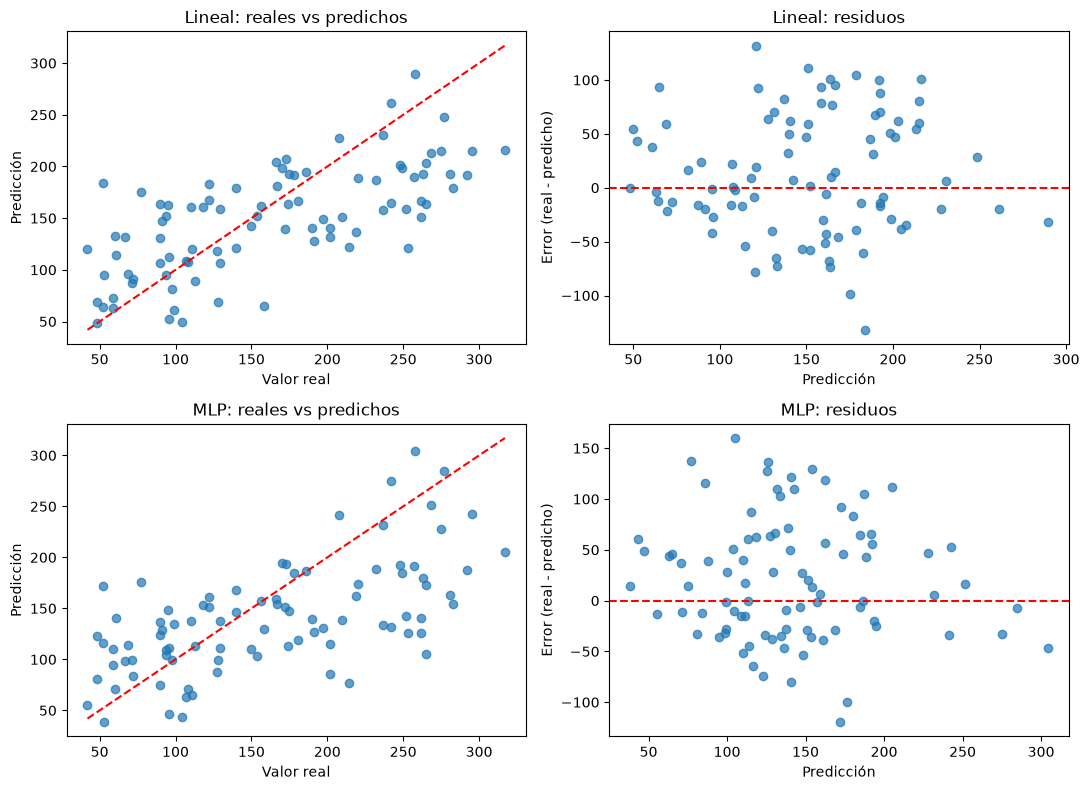

In [11]:

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for fila, nombre in enumerate(["Lineal", "MLP"]):
    pred = finales_reg[nombre].predict(X_te)
    residuos = y_te - pred

    # Valores reales frente a predichos
    axes[fila, 0].scatter(y_te, pred, alpha=0.7)
    axes[fila, 0].plot([y_te.min(), y_te.max()],
                       [y_te.min(), y_te.max()], "r--")
    axes[fila, 0].set_title(f"{nombre}: reales vs predichos")
    axes[fila, 0].set_xlabel("Valor real")
    axes[fila, 0].set_ylabel("Predicción")

    # Residuos
    axes[fila, 1].scatter(pred, residuos, alpha=0.7)
    axes[fila, 1].axhline(0, color="red", linestyle="--")
    axes[fila, 1].set_title(f"{nombre}: residuos")
    axes[fila, 1].set_xlabel("Predicción")
    axes[fila, 1].set_ylabel("Error (real - predicho)")

plt.tight_layout()
plt.show()


In [12]:

for nombre in ["Lineal", "MLP"]:
    pred = finales_reg[nombre].predict(X_te)
    errores = np.abs(y_te - pred)
    indices = np.argsort(errores)[-2:][::-1]

    print("\nModelo:", nombre)
    display(pd.DataFrame({
        "Valor real": y_te[indices],
        "Predicción": pred[indices].round(2),
        "Error absoluto": errores[indices].round(2)
    }))



Modelo: Lineal


,Valor real,Predicción,Error absoluto
0,253.0,121.03,131.97
1,52.0,183.81,131.81



Modelo: MLP


,Valor real,Predicción,Error absoluto
0,265.0,104.99,160.01
1,214.0,76.72,137.28


,Modelo,Alpha,Norma coef.,Coef. nulos,RMSE entrenamiento,RMSE validación
0,Ridge,0.10,56.8925,0,54.2851,49.1556
1,Ridge,1.00,50.5723,0,54.2966,49.2033
2,Ridge,10.00,41.0899,0,54.3951,49.3731
3,Lasso,0.01,56.5562,0,54.2853,49.1575
4,Lasso,0.10,49.2629,0,54.3023,49.2036
5,Lasso,1.00,41.0947,2,54.4733,49.5254


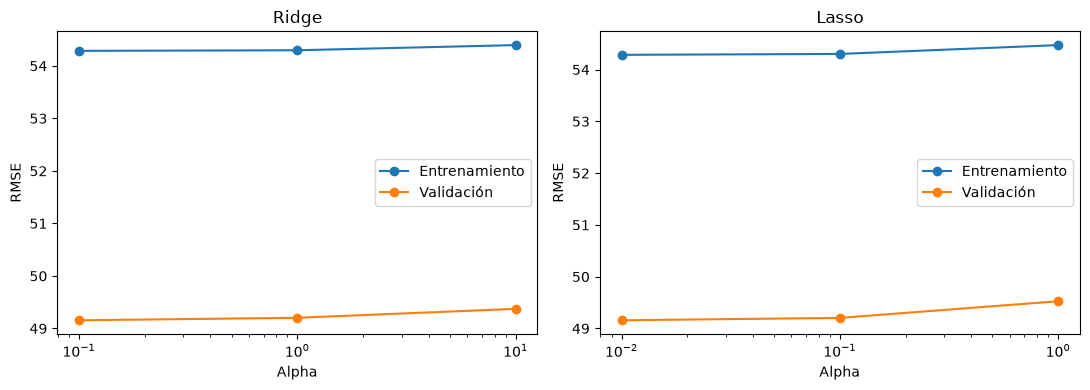

In [13]:

tabla_regularizacion = pd.DataFrame(regularizacion)
display(tabla_regularizacion.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, nombre in zip(axes, ["Ridge", "Lasso"]):
    datos = tabla_regularizacion[
        tabla_regularizacion["Modelo"] == nombre
    ]

    ax.plot(datos["Alpha"], datos["RMSE entrenamiento"],
            marker="o", label="Entrenamiento")
    ax.plot(datos["Alpha"], datos["RMSE validación"],
            marker="o", label="Validación")
    ax.set_xscale("log")
    ax.set_title(nombre)
    ax.set_xlabel("Alpha")
    ax.set_ylabel("RMSE")
    ax.legend()

plt.tight_layout()
plt.show()


### Interpretación

1. **Mejor modelo:** el mejor modelo fue el Lineal con el menor MAE	de 46.7240, RMSE de 56.9703, y R² de 0.4389 

2. **MAE frente a RMSE:** MAE mide el error absoluto promedio, mientras que RMSE penaliza más los errores grandes porque eleva las diferencias al cuadrado.
3. **R² negativo:** significa que el modelo predice peor que utilizar siempre el promedio del objetivo observado en prueba.
4. **Regularización:** al aumentar alpha, Ridge reduce la magnitud de los coeficientes y Lasso puede convertir algunos en cero. Esto reduce la complejidad del modelo, aunque una penalización excesiva puede provocar subajuste.
5. **Errores grandes:** pueden relacionarse con ruido, casos atípicos, variables insuficientes o relaciones que el modelo no consigue representar.
6. **Causalidad:** un coeficiente predictivo no demuestra que una variable cause cambios en el objetivo. Solo evidencia una asociación dentro del modelo.